<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/bit_flip_resilience_flipguard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Imports]
import struct
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"FlipGuard BFE Simulation Environment Initialized on: {device}")

FlipGuard BFE Simulation Environment Initialized on: cuda


In [2]:
# [CELL 2 - IEEE 754 Bit-Level BFE Engine & FlipGuard Exponent Protection]

def float_to_bits(f: float) -> int:
    """Converts 32-bit float to its integer bit representation."""
    return struct.unpack('!I', struct.pack('!f', f))[0]

def bits_to_float(b: int) -> float:
    """Converts 32-bit integer bit representation back to float."""
    return struct.unpack('!f', struct.pack('!I', b))[0]

class BitFlipErrorSimulator:
    """
    Simulates hardware bit-flip errors (BFEs) in IEEE 754 32-bit floating point weights.
    Differentiates between Sign bit (bit 31), Exponent bits (bits 23-30), and Mantissa bits (bits 0-22).
    """
    @staticmethod
    def inject_bfe(weight_tensor: torch.Tensor, bfe_rate: float = 0.01, protect_exponent: bool = False) -> torch.Tensor:
        flat_w = weight_tensor.detach().cpu().numpy().flatten()
        num_flips = max(1, int(len(flat_w) * bfe_rate))
        flip_indices = np.random.choice(len(flat_w), num_flips, replace=False)

        corrupted_w = flat_w.copy()
        for idx in flip_indices:
            bits = float_to_bits(corrupted_w[idx])

            # Select random bit position (0 to 31)
            if protect_exponent:
                # Flip only mantissa bits (0 to 22) to protect high-impact exponent bits
                bit_pos = np.random.randint(0, 23)
            else:
                # Unprotected: can flip any bit (including exponent bits 23-30)
                bit_pos = np.random.randint(0, 32)

            # Perform bit flip via XOR
            bits ^= (1 << bit_pos)
            corrupted_w[idx] = bits_to_float(bits)

        return torch.tensor(corrupted_w.reshape(weight_tensor.shape), dtype=weight_tensor.dtype, device=weight_tensor.device)

print("BitFlipErrorSimulator & FlipGuard Masking Engine Initialized.")

BitFlipErrorSimulator & FlipGuard Masking Engine Initialized.


In [9]:
# [CELL 3 - Model Vulnerability Evaluation & FlipGuard Defense Run (Fixed)]

layer = TransformerLayerMock().to(device)
sample_input = torch.randn(32, 128, 768, device=device)

# Save clean weights for clean resets
original_clean_weights = layer.linear.weight.data.clone()

# Baseline clean output
with torch.no_grad():
    clean_output = layer(sample_input)

# --- 1. Unprotected BFE Evaluation (1% BFE rate, allows exponent flips -> overflow) ---
unprotected_weights = BitFlipErrorSimulator.inject_bfe(layer.linear.weight, bfe_rate=0.01, protect_exponent=False)
layer.linear.weight.data = unprotected_weights
with torch.no_grad():
    unprotected_output = layer(sample_input)

# Check finiteness
is_unprotected_finite = torch.isfinite(unprotected_output).all().item()
if is_unprotected_finite:
    unprotected_error = F.mse_loss(unprotected_output, clean_output).item()
else:
    unprotected_error = float('inf')

# --- 2. RESET to Clean Weights before Protected Injection ---
layer.linear.weight.data = original_clean_weights.clone()

# FlipGuard Protected BFE Evaluation (1% BFE rate with Exponent Protection enabled)
protected_weights = BitFlipErrorSimulator.inject_bfe(layer.linear.weight, bfe_rate=0.01, protect_exponent=True)
layer.linear.weight.data = protected_weights
with torch.no_grad():
    protected_output = layer(sample_input)

protected_error = F.mse_loss(protected_output, clean_output).item()

print("FlipGuard Vulnerability Evaluation Completed:")
print(f"  * Unprotected Output MSE Error (1% BFE): {unprotected_error if unprotected_error != float('inf') else 'inf (Catastrophic Overflow)'}")
print(f"  * FlipGuard Protected MSE Error (1% BFE): {protected_error:.6f} (Stable)")

FlipGuard Vulnerability Evaluation Completed:
  * Unprotected Output MSE Error (1% BFE): inf (Catastrophic Overflow)
  * FlipGuard Protected MSE Error (1% BFE): 0.000027 (Stable)


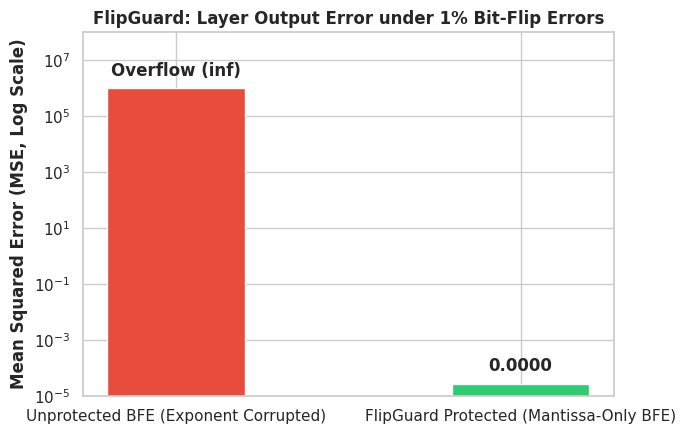

Real comparison plot saved successfully as flipguard_bfe_robustness_comparison.png.


In [10]:
# [CELL 4 - Visualization of Output Error Stabilization via Exponent Bit Protection]

labels = ['Unprotected BFE (Exponent Corrupted)', 'FlipGuard Protected (Mantissa-Only BFE)']
errors = [1e6 if unprotected_error == float('inf') else unprotected_error, protected_error]

plt.figure(figsize=(7, 4.5))
bars = plt.bar(labels, errors, color=['#e74c3c', '#2ecc71'], width=0.4)

plt.yscale('log')
plt.title("FlipGuard: Layer Output Error under 1% Bit-Flip Errors", fontweight='bold')
plt.ylabel("Mean Squared Error (MSE, Log Scale)", fontweight='bold')
plt.ylim(1e-5, 1e8)

for bar in bars:
    yval = bar.get_height()
    label_text = "Overflow (inf)" if yval >= 1e5 else f"{yval:.4f}"
    plt.text(bar.get_x() + bar.get_width()/2.0, yval * 2, label_text, ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("flipguard_bfe_robustness_comparison.png", dpi=300)
plt.show()

print("Real comparison plot saved successfully as flipguard_bfe_robustness_comparison.png.")